Literature fit: uptake ∝ (cross-linker)^-0.50
  50 µL = 0.55 wt% of acrylic acid -> literature trend predicts ≈ 10,794%
  100 µL = 1.09 wt% of acrylic acid -> literature trend predicts ≈ 7,627%
  200 µL = 2.18 wt% of acrylic acid -> literature trend predicts ≈ 5,389%


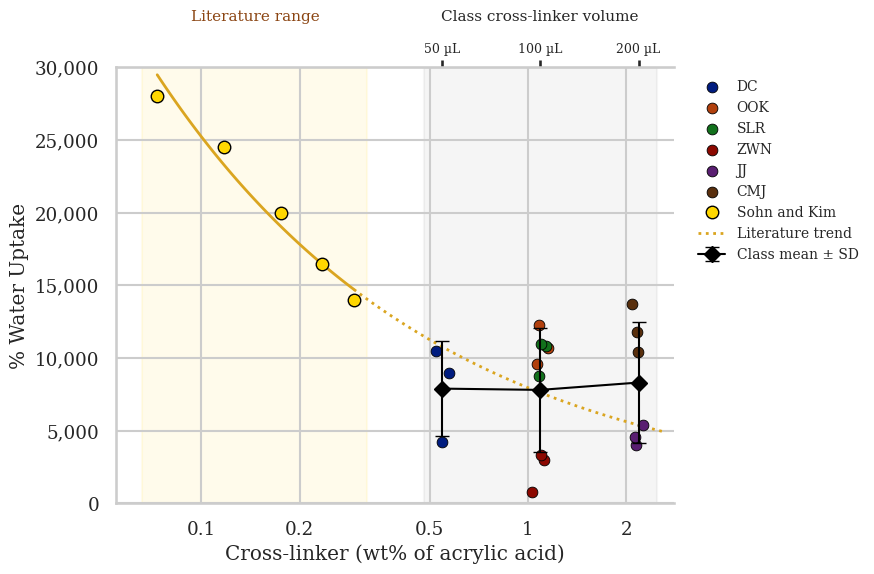

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.transforms as mtrans
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk", font_scale=0.8)
plt.rcParams["font.family"] = "serif"


data = {
    ("DC", 50):   [4200, 9000, 10500],
    ("OOK", 100): [10700, 9600, 12300],
    ("SLR", 100): [10800, 8800, 11000],
    ("ZWN", 100): [800, 3000, 3300],
    ("JJ", 200):  [4000, 5400, 4600],
    ("CMJ", 200): [10400, 13700, 11800],
}
df = pd.DataFrame([{"Group": g, "Cross-linker (µL)": c, "% Water Uptake": v}
                   for (g, c), vals in data.items() for v in vals])


RHO_EDA, AA_MASS = 1.09, 10.0
vol_to_wt = {v: v / 1000 * RHO_EDA / AA_MASS * 100 for v in (50, 100, 200)}
df["XL (wt%)"] = df["Cross-linker (µL)"].map(vol_to_wt)


lit_soln_wt = np.array([0.025, 0.04, 0.06, 0.08, 0.10])
lit_x = lit_soln_wt * 61.0 / 20.8

b, ln_a = np.polyfit(np.log(lit_x), np.log(lit_y), 1)
fit = lambda x: np.exp(ln_a) * x ** b
x_fit = np.geomspace(lit_x.min(), lit_x.max(), 50)
x_ext = np.geomspace(lit_x.max(), 2.6, 50)
print(f"Literature fit: uptake ∝ (cross-linker)^{b:.2f}")
for v, x in vol_to_wt.items():
    print(f"  {v} µL = {x:.2f} wt% of acrylic acid -> literature trend predicts ≈ {fit(x):,.0f}%")


fig, ax = plt.subplots(figsize=(9, 6))
groups = [g for g, _ in data]
colors = dict(zip(groups, sns.color_palette("dark", len(groups))))
rng = np.random.default_rng(1)
for g in groups:
    sub = df[df["Group"] == g]
    jitter = np.exp(rng.uniform(-0.06, 0.06, len(sub)))
    ax.scatter(sub["XL (wt%)"] * jitter, sub["% Water Uptake"], s=60, color=colors[g],
               edgecolor="black", linewidth=0.6, label=g, zorder=3)

lvl = df.groupby("XL (wt%)")["% Water Uptake"].agg(["mean", "std"])
ax.errorbar(lvl.index, lvl["mean"], yerr=lvl["std"], fmt="D-", color="black",
            ms=8, lw=1.5, capsize=5, label="Class mean ± SD", zorder=4)

ax.plot(lit_x, lit_y, "o", color="gold", mec="black", ms=9, zorder=5, label="Sohn and Kim")
ax.plot(x_fit, fit(x_fit), "-", color="goldenrod", lw=2, zorder=2)
ax.plot(x_ext, fit(x_ext), ":", color="goldenrod", lw=2, zorder=2, label="Literature trend")

ax.axvspan(lit_x.min() * 0.9, lit_x.max() * 1.1, color="gold", alpha=0.08, zorder=0)
ax.axvspan(vol_to_wt[50] * 0.88, vol_to_wt[200] * 1.14, color="gray", alpha=0.08, zorder=0)

ax.set_xscale("log")
ax.set_xticks([0.05, 0.1, 0.2, 0.5, 1, 2])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x:g}"))
ax.set(xlabel="Cross-linker (wt% of acrylic acid)", ylabel="% Water Uptake",
       ylim=(0, 30000), xlim=(0.055, 2.8))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x:,.0f}"))

top = ax.secondary_xaxis("top")
top.set_xticks(list(vol_to_wt.values()), [f"{v} µL" for v in vol_to_wt])
top.xaxis.set_minor_locator(mtick.NullLocator())
top.tick_params(axis="x", length=5, labelsize=9)
blend = mtrans.blended_transform_factory(ax.transData, ax.transAxes)
ax.text(vol_to_wt[100], 1.10, "Class cross-linker volume", ha="center", va="bottom",
        fontsize=11, transform=blend)
ax.text(np.sqrt(lit_x.min() * lit_x.max()), 1.10, "Literature range", ha="center", va="bottom",
        fontsize=11, color="saddlebrown", transform=blend)

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig("FigureX_crosslinker.png", dpi=300)
plt.show()

